# 03 — Expériences sur la validation : hypothèses et verdicts

**Objectif** : tester, une par une, les hypothèses de conception du projet, puis figer les choix avant de toucher au jeu de test.

Ce notebook ne fait **aucun entraînement de réseau**. Il lit les fichiers `results/runs/*.json` produits par `python -m src.experiments` (groupes `fd001`, `grid`, `fd004`, `cv`).

## Hypothèses

Elles ont été écrites dans le plan du projet, **avant** les expériences. Le but n'est pas qu'elles soient vraies, mais de savoir lesquelles le sont.

| | Hypothèse | Raison de la poser |
| --- | --- | --- |
| H1 | Un réseau récurrent fait mieux qu'un MLP sur la même fenêtre | Le MLP aplatit la fenêtre et ignore l'ordre des cycles |
| H2 | GRU et LSTM sont équivalents | Sur des séquences courtes, le GRU est réputé aussi bon avec moins de paramètres |
| H3 | Empiler deux couches, ou lire dans les deux sens, améliore le LSTM | Plus de capacité |
| H4 | Sur FD004, normaliser par régime est nécessaire | Le régime masque la dégradation (notebook 01) |
| H5 | Une branche « contexte » qui reçoit le régime de vol améliore la prédiction | Le régime a un sens physique |
| H6 | Apprendre aussi l'état du moteur (multi-tâche) améliore la régression | La seconde tâche régularise l'encodeur |
| H7 | Le réseau retenu bat la meilleure baseline réglée | Critère de succès du projet |

## Règle de décision

- Chaque configuration est entraînée avec **5 graines**. On compare les RMSE de validation de deux configurations par un **test de Welch** (test t à variances inégales).
- Une hypothèse du type « A fait mieux que B » est **confirmée** si A est meilleur et p < 0,05 ; **réfutée** si B est meilleur et p < 0,05 ; **non concluante** sinon.
- Une hypothèse d'équivalence est **réfutée** si p < 0,05, **non réfutée** sinon (ce qui ne prouve pas l'équivalence).

**Limites de cette règle**, à garder en tête : 5 graines donnent un test peu puissant ; les graines ne mesurent que le hasard de l'initialisation, pas celui du découpage (traité en section 5) ; avec une douzaine de tests à 5 %, un faux positif est plausible.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est rangé dans notebooks/ : on se place à la racine du projet,
# pour que les chemins relatifs (data/raw, results, models) fonctionnent partout.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import set_plot_style

set_plot_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def say(text: str) -> None:
    """Affiche une phrase dont les chiffres viennent du code, pas d'une saisie manuelle."""
    from IPython.display import Markdown, display

    display(Markdown(text))

from src.data import prepare
from src.experiments import EXPERIMENTS
from src.train import apply_overrides
from src.utils import load_config


def bundle_for(name: str, **data_overrides) -> dict:
    """Données (découpage, normalisation, fenêtres) de l'expérience `name` du registre."""
    _, base, overrides = EXPERIMENTS[name]
    cfg = apply_overrides(load_config(base), overrides | {f"data.{k}": v for k, v in data_overrides.items()})
    return prepare(cfg["data"], cfg["seed"])

import json

from scipy.stats import ttest_rel

from src.baselines import BOOSTING, FOREST, forest_params, run_baselines
from src.experiments import compare, runs_table, summary

runs = runs_table()
# Les baselines réglées (notebook 02) sont ajoutées comme des expériences ordinaires
bl = pd.read_csv("results/baselines_validation.csv")
bl["name"] = bl["modèle"].map({FOREST: "rf_", BOOSTING: "gb_"}) + bl["jeu"]
runs = pd.concat([runs, bl.dropna(subset="name")[["name", "seed", "rmse", "mae", "nasa"]]], ignore_index=True)
summary().round(3).to_csv("results/validation_summary.csv")

LABELS = {
    "mlp_fd001": "MLP", "lstm_fd001": "LSTM", "gru_fd001": "GRU", "lstm2_fd001": "LSTM empilé (2 couches)",
    "bilstm_fd001": "LSTM bidirectionnel", "lstm_best_fd001": "LSTM, W = 40", "gru_best_fd001": "GRU, W = 40",
    "multitask_fd004": "référence multi-tâche", "abl_global_norm": "normalisation globale",
    "abl_no_context": "sans contexte", "abl_monotask": "régression seule", "abl_lstm": "encodeur LSTM",
    "lam_0.3": "λ = 0,3", "lam_0.7": "λ = 0,7", "multitask_w40_fd004": "multi-tâche, W = 40",
    "abl_monotask_w40": "régression seule, W = 40",
    "rf_FD001": "Random Forest réglé", "rf_FD004": "Random Forest réglé",
    "gb_FD001": "gradient boosting", "gb_FD004": "gradient boosting",
}
VERDICTS = []


def score(name: str) -> str:
    values = runs.loc[runs["name"] == name, "rmse"]
    return f"{values.mean():.2f} ± {values.std():.2f}"


def tester(code: str, a: str, b: str, attendu: str = "a < b") -> None:
    """Teste « a fait mieux que b » (ou « a = b ») sur la RMSE de validation et affiche le verdict."""
    r = compare(a, b, runs=runs)
    significatif = r["p"] < 0.05
    if attendu == "a = b":
        verdict = "réfutée" if significatif else "non réfutée"
    else:
        verdict = ("confirmée" if r["diff"] < 0 else "réfutée") if significatif else "non concluante"
    VERDICTS.append({"hypothèse": code, "comparaison": f"{LABELS[a]} contre {LABELS[b]}", "écart (cycles)": round(r["diff"], 2),
                     "p": round(r["p"], 4), "verdict": verdict})
    say(f"**{code} — {verdict}.** {LABELS[a]} : {score(a)} ; {LABELS[b]} : {score(b)} ; "
        f"écart {r['diff']:+.2f} cycle, p = {r['p']:.3f}.")


def barres(names: list, title: str, reference: str | None = None):
    """RMSE de validation moyenne ± écart-type, de la meilleure à la moins bonne."""
    stats = runs[runs["name"].isin(names)].groupby("name")["rmse"].agg(["mean", "std"]).sort_values("mean")
    fig, ax = plt.subplots(figsize=(9, 0.45 * len(stats) + 1.3))
    ax.barh([LABELS[n] for n in stats.index], stats["mean"], xerr=stats["std"], capsize=3)
    ax.invert_yaxis()
    ax.set_xlim(left=stats["mean"].min() - 2.5)
    ax.set_xlabel("RMSE de validation (cycles) — moyenne ± écart-type sur 5 graines")
    ax.set_title(title)
    if reference:
        value = runs.loc[runs["name"] == reference, "rmse"].mean()
        ax.axvline(value, color="tab:red", linestyle="--", label=LABELS[reference])
        ax.legend(loc="lower right")
    return fig

## 1. FD001 : architectures (H1, H2, H3)

**Protocole** : même découpage, mêmes 14 capteurs, fenêtre W = 30, taille cachée 64. Seule l'architecture change.

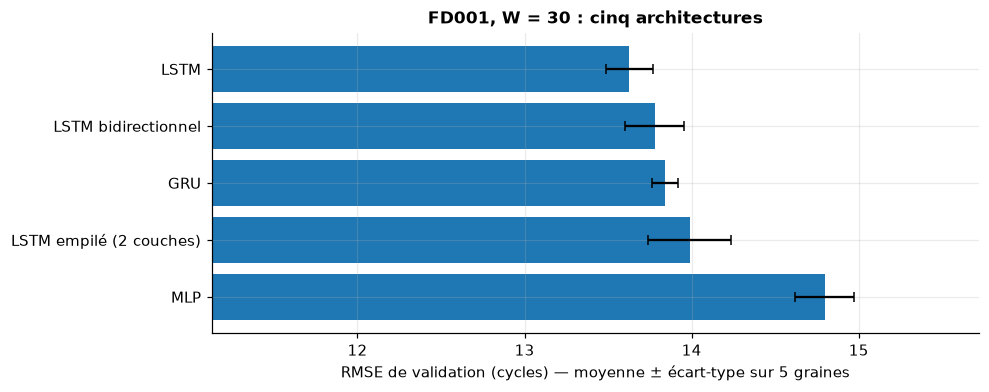

**H1 — confirmée.** LSTM : 13.63 ± 0.14 ; MLP : 14.80 ± 0.18 ; écart -1.17 cycle, p = 0.000.

**H2 — réfutée.** GRU : 13.84 ± 0.08 ; LSTM : 13.63 ± 0.14 ; écart +0.21 cycle, p = 0.024.

**H3 (empilé) — réfutée.** LSTM empilé (2 couches) : 13.99 ± 0.25 ; LSTM : 13.63 ± 0.14 ; écart +0.36 cycle, p = 0.028.

**H3 (bidirectionnel) — non concluante.** LSTM bidirectionnel : 13.78 ± 0.18 ; LSTM : 13.63 ± 0.14 ; écart +0.15 cycle, p = 0.174.

In [2]:
barres(["mlp_fd001", "lstm_fd001", "gru_fd001", "lstm2_fd001", "bilstm_fd001"], "FD001, W = 30 : cinq architectures")
plt.show()

tester("H1", "lstm_fd001", "mlp_fd001")
tester("H2", "gru_fd001", "lstm_fd001", attendu="a = b")
tester("H3 (empilé)", "lstm2_fd001", "lstm_fd001")
tester("H3 (bidirectionnel)", "bilstm_fd001", "lstm_fd001")

**Interprétation**
- H1 : l'ordre des cycles porte de l'information qu'un MLP sur fenêtre aplatie n'exploite pas aussi bien.
- H3 : ajouter de la capacité n'aide pas. Les verdicts ci-dessus disent si elle est neutre ou nuisible. Explication plausible : avec une centaine de moteurs, le facteur limitant est la quantité de données, pas la taille du réseau.
- Ces verdicts valent pour W = 30 et une taille cachée de 64 ; la section suivante fait varier ces réglages.

## 2. Recherche d'hyperparamètres (exploratoire)

Cette section n'est pas un test d'hypothèse : c'est une **exploration**. Grille complète de 36 essais sur le LSTM de FD001 : hidden ∈ {32, 64, 128}, couches ∈ {1, 2}, W ∈ {20, 30, 40}, dropout ∈ {0,1 ; 0,3}. Une seule graine par essai, donc aucun essai isolé n'est fiable : on regarde l'effet moyen de chaque paramètre.

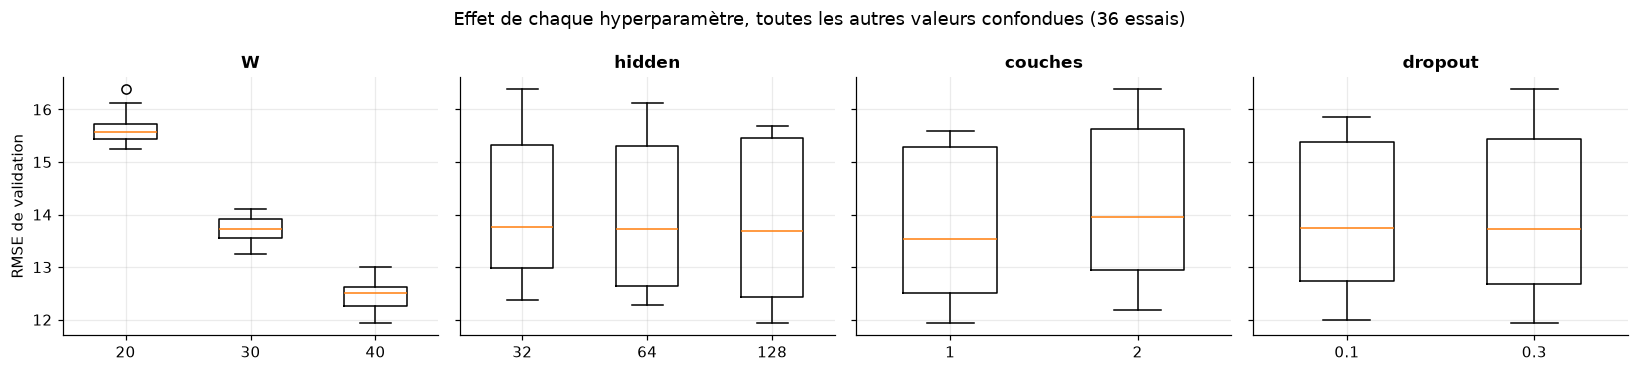

Écart de RMSE moyenne entre la meilleure et la moins bonne valeur de chaque paramètre : **W** 3.19 ; **hidden** 0.25 ; **couches** 0.40 ; **dropout** 0.07.

Meilleur essai : W = 40, hidden = 128, 1 couche(s), dropout 0.3 (RMSE 11.93). Les 10 essais sur les 10 meilleurs ont W = 40.

In [3]:
summary_table = summary()
grid = summary_table[summary_table.index.str.startswith("grid_")]
params = grid.index.str.extract(r"grid_h(\d+)_l(\d+)_w(\d+)_d([\d.]+)")
params.columns, params.index = ["hidden", "couches", "W", "dropout"], grid.index
grid = params.astype({"hidden": int, "couches": int, "W": int, "dropout": float}).assign(rmse=grid["rmse_mean"])

fig, axes = plt.subplots(1, 4, figsize=(15, 3.4), sharey=True)
for ax, col in zip(axes, ["W", "hidden", "couches", "dropout"]):
    values = sorted(grid[col].unique())
    ax.boxplot([grid.loc[grid[col] == v, "rmse"] for v in values], tick_labels=values, widths=0.5)
    ax.set_title(col)
axes[0].set_ylabel("RMSE de validation")
fig.suptitle(f"Effet de chaque hyperparamètre, toutes les autres valeurs confondues ({len(grid)} essais)")
plt.tight_layout()
plt.show()

effets = {col: grid.groupby(col)["rmse"].mean() for col in ["W", "hidden", "couches", "dropout"]}
say("Écart de RMSE moyenne entre la meilleure et la moins bonne valeur de chaque paramètre : "
    + " ; ".join(f"**{col}** {e.max() - e.min():.2f}" for col, e in effets.items()) + ".")
best = grid.sort_values("rmse").iloc[0]
say(f"Meilleur essai : W = {best['W']:.0f}, hidden = {best['hidden']:.0f}, {best['couches']:.0f} couche(s), dropout {best['dropout']} "
    f"(RMSE {best['rmse']:.2f}). Les {(grid.sort_values('rmse').head(10)['W'] == 40).sum()} essais sur les 10 meilleurs ont W = 40.")

**Lecture** : la taille de fenêtre domine tous les autres paramètres. L'effet de la taille cachée, du nombre de couches et du dropout est du même ordre que le bruit entre graines mesuré en section 1 : le choix de `hidden = 128` repose sur un seul essai et reste fragile.

**Hypothèse issue de l'exploration** — H8 : *allonger la fenêtre de 30 à 40 cycles améliore le réseau*. Une hypothèse née d'une exploration doit être confirmée sur des entraînements **nouveaux**. La configuration retenue (W = 40, hidden = 128, 1 couche, dropout 0,3) est donc relancée avec 5 graines, pour le LSTM et pour le GRU.

In [4]:
tester("H8 (GRU)", "gru_best_fd001", "gru_fd001")
tester("H8 (LSTM)", "lstm_best_fd001", "lstm_fd001")
tester("H2 (à W = 40)", "gru_best_fd001", "lstm_best_fd001", attendu="a = b")

**H8 (GRU) — confirmée.** GRU, W = 40 : 12.23 ± 0.08 ; GRU : 13.84 ± 0.08 ; écart -1.61 cycle, p = 0.000.

**H8 (LSTM) — confirmée.** LSTM, W = 40 : 12.29 ± 0.29 ; LSTM : 13.63 ± 0.14 ; écart -1.34 cycle, p = 0.000.

**H2 (à W = 40) — non réfutée.** GRU, W = 40 : 12.23 ± 0.08 ; LSTM, W = 40 : 12.29 ± 0.29 ; écart -0.06 cycle, p = 0.682.

Réserve sur H8 : la comparaison change deux choses à la fois (W et la taille cachée). La grille indique que W porte l'essentiel de l'effet, mais le test ne les sépare pas.

**Choix pour FD001** : entre GRU et LSTM à W = 40, on retient le **GRU**. Critère posé d'avance : à performance non distinguable, le modèle le plus léger.

## 3. FD004 : ablations (H4, H5, H6)

**Modèle de référence** : un GRU lit la séquence de capteurs ; un petit MLP encode le régime de vol du dernier cycle (le « contexte ») ; les deux vecteurs sont concaténés ; une tête prédit la RUL, l'autre l'état. Perte = λ · MSE + (1 − λ) · entropie croisée pondérée, λ = 0,5, fenêtre W = 30.

**Protocole** : chaque ablation retire ou change **une seule chose** par rapport à la référence.

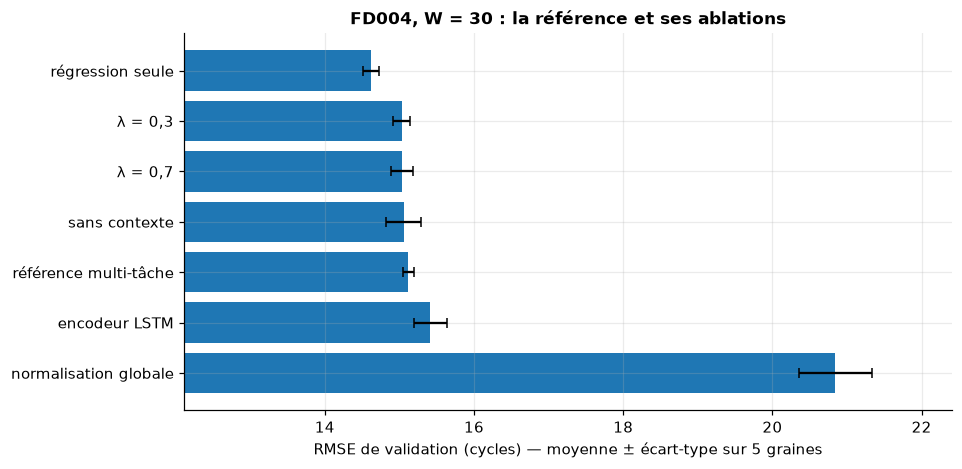

**H4 — confirmée.** référence multi-tâche : 15.12 ± 0.08 ; normalisation globale : 20.84 ± 0.49 ; écart -5.72 cycle, p = 0.000.

**H5 — non concluante.** référence multi-tâche : 15.12 ± 0.08 ; sans contexte : 15.06 ± 0.23 ; écart +0.06 cycle, p = 0.593.

**H6 — réfutée.** référence multi-tâche : 15.12 ± 0.08 ; régression seule : 14.62 ± 0.11 ; écart +0.50 cycle, p = 0.000.

**H2 (FD004) — réfutée.** référence multi-tâche : 15.12 ± 0.08 ; encodeur LSTM : 15.42 ± 0.23 ; écart -0.29 cycle, p = 0.041.

**λ = 0,3 — non réfutée.** λ = 0,3 : 15.03 ± 0.12 ; référence multi-tâche : 15.12 ± 0.08 ; écart -0.09 cycle, p = 0.191.

**λ = 0,7 — non réfutée.** λ = 0,7 : 15.03 ± 0.15 ; référence multi-tâche : 15.12 ± 0.08 ; écart -0.09 cycle, p = 0.303.

In [5]:
fig = barres(["multitask_fd004", "abl_monotask", "abl_no_context", "abl_lstm", "abl_global_norm", "lam_0.3", "lam_0.7"],
             "FD004, W = 30 : la référence et ses ablations")
fig.savefig("assets/ablations_fd004.png", dpi=150, bbox_inches="tight")
plt.show()

tester("H4", "multitask_fd004", "abl_global_norm")
tester("H5", "multitask_fd004", "abl_no_context")
tester("H6", "multitask_fd004", "abl_monotask")
tester("H2 (FD004)", "multitask_fd004", "abl_lstm", attendu="a = b")
tester("λ = 0,3", "lam_0.3", "multitask_fd004", attendu="a = b")
tester("λ = 0,7", "lam_0.7", "multitask_fd004", attendu="a = b")

**Interprétation**
- **H4** : c'est l'effet le plus fort du projet. Il confirme ce que l'analyse exploratoire laissait prévoir.
- **H5** : aucun gain détectable. Cela ne dit pas que le régime de vol est sans intérêt, mais que, **une fois les capteurs normalisés par régime**, le redonner au modèle n'apporte rien de mesurable. Deux réserves : la branche ne reçoit que le régime du dernier cycle, et elle n'a pas été testée avec une normalisation globale, où elle aurait peut-être servi.
- **H6** : la seconde tâche ne joue pas le rôle de régularisation espéré. La perte totale partage la capacité du réseau entre deux objectifs.
- λ : dans la plage testée, le réglage n'a pas d'effet détectable.
- **H2** : à rapprocher des verdicts H2 des sections 1 et 2. Le sens de l'écart entre GRU et LSTM change d'un contexte à l'autre, et les deux écarts significatifs sont faibles : aucun des deux encodeurs n'est systématiquement meilleur.

### La classification coûte-t-elle aussi à W = 40 ?

L'ablation H6 a été faite à W = 30. La fenêtre retenue étant W = 40, on la refait à cette taille, et on regarde ce que la tête de classification apporte en échange.

In [6]:
tester("H6 (à W = 40)", "multitask_w40_fd004", "abl_monotask_w40")
tester("H8 (FD004)", "multitask_w40_fd004", "multitask_fd004")

clf = runs[runs["name"].isin(["multitask_w40_fd004", "multitask_fd004"])].groupby("name")[["f1_macro", "recall_critical"]].agg(["mean", "std"])
clf.index = [LABELS[n] for n in clf.index]
display(clf.round(3))

**H6 (à W = 40) — réfutée.** multi-tâche, W = 40 : 14.09 ± 0.16 ; régression seule, W = 40 : 13.45 ± 0.16 ; écart +0.65 cycle, p = 0.000.

**H8 (FD004) — confirmée.** multi-tâche, W = 40 : 14.09 ± 0.16 ; référence multi-tâche : 15.12 ± 0.08 ; écart -1.03 cycle, p = 0.000.

f1_macro        recall_critical       
                          mean    std            mean    std
référence multi-tâche    0.862  0.005           0.937  0.008
multi-tâche, W = 40      0.889  0.006           0.935  0.008

**Choix pour FD004**. Le cahier des charges demande deux sorties : la RUL **et** l'état du moteur. Le modèle final est donc le multi-tâche à W = 40, même si la régression seule est aussi bonne ou meilleure en RMSE : le verdict H6 ci-dessus chiffre ce que cette seconde sortie coûte. La branche contexte est conservée par cohérence avec la référence, en sachant qu'elle n'apporte rien de mesurable.

## 4. Le réseau bat-il la baseline réglée ? (H7)

Comparaison à données et fenêtre identiques (W = 40), 5 graines de chaque côté.

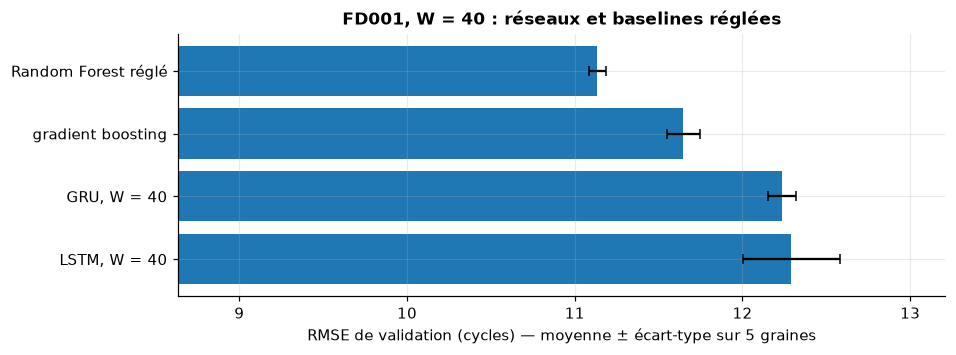

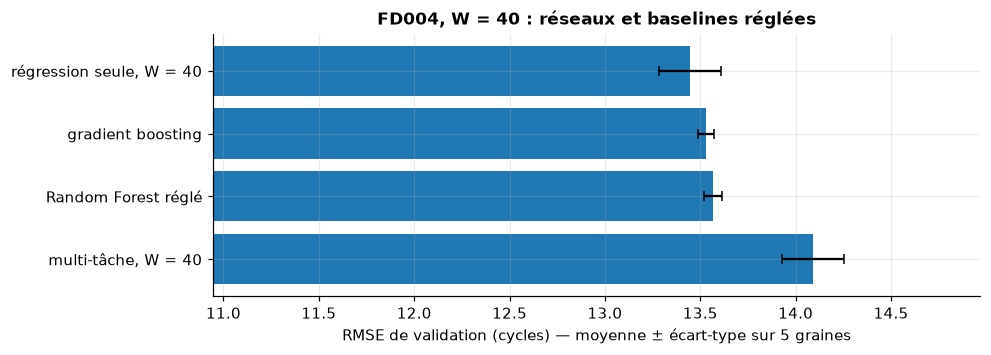

**H7 (FD001) — réfutée.** GRU, W = 40 : 12.23 ± 0.08 ; Random Forest réglé : 11.14 ± 0.05 ; écart +1.10 cycle, p = 0.000.

**H7 (FD004) — réfutée.** multi-tâche, W = 40 : 14.09 ± 0.16 ; Random Forest réglé : 13.57 ± 0.05 ; écart +0.53 cycle, p = 0.001.

In [7]:
fig = barres(["gru_best_fd001", "lstm_best_fd001", "rf_FD001", "gb_FD001"], "FD001, W = 40 : réseaux et baselines réglées")
plt.show()
fig = barres(["multitask_w40_fd004", "abl_monotask_w40", "rf_FD004", "gb_FD004"], "FD004, W = 40 : réseaux et baselines réglées")
plt.show()

tester("H7 (FD001)", "gru_best_fd001", "rf_FD001")
tester("H7 (FD004)", "multitask_w40_fd004", "rf_FD004")

C'est le résultat le plus important du notebook, et il va contre l'attente de départ. Trois explications possibles, **non départagées ici** :
1. Les caractéristiques de fenêtre (moyenne, pente) résument déjà l'essentiel du signal ; le réseau doit les réapprendre à partir d'une centaine de moteurs.
2. Les réseaux sont sous-réglés : une seule architecture, un seul optimiseur, pas d'augmentation de données.
3. La cible plafonnée rend le problème presque statique : il s'agit moins de suivre une dynamique que de reconnaître un niveau de dégradation.

Le jeu de test dira si cet écart tient hors de la validation.

## 5. Les conclusions dépendent-elles du découpage ?

Toutes les comparaisons précédentes reposent sur **un seul** découpage train / validation. Les 5 graines mesurent le hasard de l'initialisation, pas celui du choix des moteurs de validation. On refait donc la comparaison H7 en **validation croisée par moteur à 5 plis** : chaque moteur sert une fois en validation. Réseau et forêt sont entraînés sur les mêmes plis (une graine par pli).

In [8]:
rows = []
for jeu, cv_name in [("FD001", "cv_gru_fd001"), ("FD004", "cv_multitask_fd004")]:
    for fold in range(5):
        run = json.loads(Path(f"results/runs/{cv_name}_fold{fold}_seed0.json").read_text(encoding="utf-8"))
        bundle = bundle_for(f"{cv_name}_fold{fold}")
        rf = run_baselines(bundle["train"], {jeu: bundle["val"]}, forest=forest_params(jeu)).set_index("modèle")
        rows.append({"jeu": jeu, "pli": fold, "moteurs de validation": bundle["val_df"]["unit"].nunique(),
                     "réseau": run["val"]["rmse"], "Random Forest réglé": rf.loc[FOREST, "rmse"]})
cv = pd.DataFrame(rows)
cv["écart"] = cv["réseau"] - cv["Random Forest réglé"]
cv.to_csv("results/cross_validation.csv", index=False)
display(cv.round(2).set_index(["jeu", "pli"]))

for jeu, g in cv.groupby("jeu"):
    p = ttest_rel(g["réseau"], g["Random Forest réglé"]).pvalue
    seed_std = runs.loc[runs["name"] == {"FD001": "gru_best_fd001", "FD004": "multitask_w40_fd004"}[jeu], "rmse"].std()
    say(f"**{jeu}** — réseau : {g['réseau'].mean():.2f} ± {g['réseau'].std():.2f} ; forêt : {g['Random Forest réglé'].mean():.2f} ± "
        f"{g['Random Forest réglé'].std():.2f} ; écart moyen {g['écart'].mean():+.2f} cycle, la forêt est meilleure dans "
        f"{(g['écart'] > 0).sum()} plis sur 5 (test t apparié : p = {p:.3f}). "
        f"L'écart-type entre plis ({g['réseau'].std():.2f}) est {g['réseau'].std() / seed_std:.0f} fois celui entre graines ({seed_std:.2f}).")

moteurs de validation  réseau  Random Forest réglé  écart
jeu   pli                                                           
FD001 0                       20   12.69                12.53   0.17
      1                       20   11.71                11.64   0.07
      2                       20   11.92                11.65   0.27
      3                       20   11.87                11.49   0.38
      4                       20   11.89                10.64   1.25
FD004 0                       50   13.16                12.67   0.49
      1                       50   14.90                14.95  -0.06
      2                       50   13.31                12.98   0.34
      3                       50   13.37                12.67   0.70
      4                       49   16.24                15.85   0.40

**FD001** — réseau : 12.02 ± 0.39 ; forêt : 11.59 ± 0.67 ; écart moyen +0.43 cycle, la forêt est meilleure dans 5 plis sur 5 (test t apparié : p = 0.115). L'écart-type entre plis (0.39) est 5 fois celui entre graines (0.08).

**FD004** — réseau : 14.20 ± 1.34 ; forêt : 13.82 ± 1.48 ; écart moyen +0.37 cycle, la forêt est meilleure dans 4 plis sur 5 (test t apparié : p = 0.040). L'écart-type entre plis (1.34) est 8 fois celui entre graines (0.16).

**Ce que cela change**
- Le score dépend bien plus des moteurs tirés en validation que de la graine. Un écart-type « sur 5 graines » sous-estime donc l'incertitude réelle d'un score ; c'est une limite de toutes les comparaisons des sections 1 à 4.
- Ce qui compte pour H7 est l'écart **apparié** pli par pli, affiché ci-dessus : il dit si le classement réseau / forêt se maintient quand les moteurs changent.
- Réserve : les hyperparamètres (réseau et forêt) ont été choisis sur le découpage d'origine, pas refaits dans chaque pli.

## 6. Synthèse des verdicts

In [9]:
verdicts = pd.DataFrame(VERDICTS).set_index("hypothèse")
verdicts.to_csv("results/verdicts.csv")
verdicts

,comparaison,écart (cycles),p,verdict
hypothèse,,,,
H1,LSTM contre MLP,-1.17,0.0000,confirmée
H2,GRU contre LSTM,0.21,0.0240,réfutée
H3 (empilé),LSTM empilé (2 couches) contre LSTM,0.36,0.0277,réfutée
H3 (bidirectionnel),LSTM bidirectionnel contre LSTM,0.15,0.1740,non concluante
H8 (GRU),"GRU, W = 40 contre GRU",-1.61,0.0000,confirmée
H8 (LSTM),"LSTM, W = 40 contre LSTM",-1.34,0.0001,confirmée
H2 (à W = 40),"GRU, W = 40 contre LSTM, W = 40",-0.06,0.6816,non réfutée
H4,référence multi-tâche contre normalisation glo...,-5.72,0.0000,confirmée
H5,référence multi-tâche contre sans contexte,0.06,0.5931,non concluante


## 7. Choix figés avant le test

| Jeu | Modèle retenu | Critère |
| --- | --- | --- |
| FD001 | GRU, W = 40, hidden = 128, 1 couche, dropout 0,3 | Meilleure configuration de la grille, confirmée sur 5 graines ; GRU plutôt que LSTM car plus léger à performance non distinguable |
| FD004 | GRU multi-tâche avec contexte, W = 40, hidden = 64, λ = 0,5, normalisation par régime | Deux sorties exigées par le cahier des charges ; W = 40 confirmé sur 5 graines |
| Baseline | Random Forest réglé (`results/forest_params.json`) | Meilleure baseline sur la validation de FD001 ; au niveau du gradient boosting sur FD004 |

Ces choix ne changent plus. `04_evaluation.ipynb` les mesure sur le jeu de test officiel, qui n'a servi à aucune décision.